<a href="https://colab.research.google.com/github/239-blip/mssp607/blob/main/WeeklyModules/Week08/PARTICIPATION_ACTIVITY_Week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!git clone https://github.com/239-blip/mssp607
%cd /content/mssp607
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

fatal: destination path 'mssp607' already exists and is not an empty directory.
/content/mssp607


In [5]:
df = pd.read_csv(
    "WeeklyModules/Week08/InternetSales.csv",
    encoding='latin-1',
    usecols=['OrderDate', 'EnglishProductName',
             'SalesAmount', 'OrderQuantity']
)
df['OrderDate'] = pd.to_datetime(
    df['OrderDate'], format='%m/%d/%Y'
)

In [6]:
# 2. Summary statistics by product
product_summary = (
    df.groupby('EnglishProductName')
    .agg(
        total_sales=('SalesAmount', 'sum'),
        units_sold=('OrderQuantity', 'sum'),
        average_sales=('SalesAmount', 'mean')
    ).sort_values('total_sales', ascending=False)
)

print("Top products:")
print(product_summary.head(10))

Top products:
                          total_sales  units_sold  average_sales
EnglishProductName                                              
Mountain-200 Black, 46   1.373470e+06         620    2215.273465
Mountain-200 Black, 42   1.363142e+06         614    2220.101129
Mountain-200 Silver, 38  1.339463e+06         596    2247.420789
Mountain-200 Silver, 46  1.301100e+06         580    2243.276032
Mountain-200 Black, 38   1.294866e+06         582    2224.855913
Mountain-200 Silver, 42  1.257435e+06         560    2245.418880
Road-150 Red, 48         1.205877e+06         337    3578.270000
Road-150 Red, 62         1.202299e+06         336    3578.270000
Road-150 Red, 52         1.080638e+06         302    3578.270000
Road-150 Red, 56         1.055590e+06         295    3578.270000


In [7]:
# 3. Monthly sales for complete years
history = df[
    df['OrderDate'].dt.year.between(2011, 2013)
]

monthly = (
    history.set_index('OrderDate')['SalesAmount']
    .resample('MS')
    .sum()
)

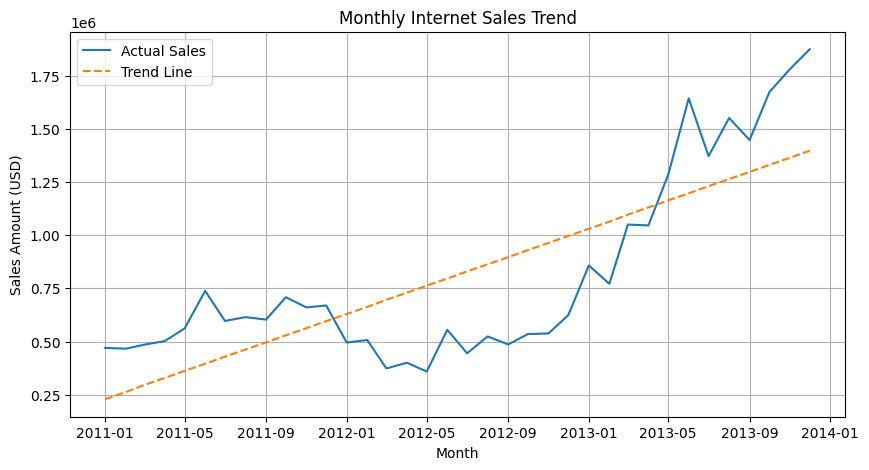

In [8]:
# 4. Fit an OLS trend line
x = np.arange(len(monthly))
X = sm.add_constant(x)

ols_model = sm.OLS(monthly.values, X).fit()
trend = ols_model.fittedvalues

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly, label='Actual Sales')
plt.plot(monthly.index, trend, '--', label='Trend Line')
plt.title('Monthly Internet Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Amount (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# 5. ARIMA forecast for 60 months
model = ARIMA(monthly, order=(1, 1, 1))
results = model.fit()

forecast = results.get_forecast(
    steps=60
).predicted_mean

# Convert monthly forecasts to annual totals
annual_forecast = forecast.resample('YS').sum()
print("Five-year sales forecast:")
print(annual_forecast.round(2))

Five-year sales forecast:
2014-01-01    22337774.85
2015-01-01    22342430.50
2016-01-01    22342440.28
2017-01-01    22342440.30
2018-01-01    22342440.30
Freq: YS-JAN, Name: predicted_mean, dtype: float64


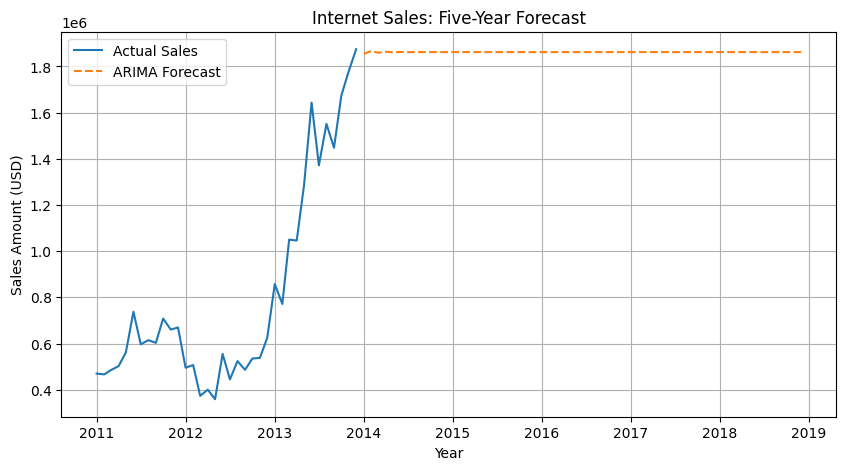

In [10]:
# 6. Plot the forecast
plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly, label='Actual Sales')
plt.plot(forecast.index, forecast,
         '--', label='ARIMA Forecast')
plt.title('Internet Sales: Five-Year Forecast')
plt.xlabel('Year')
plt.ylabel('Sales Amount (USD)')
plt.legend()
plt.grid(True)
plt.show()